# 01 · Auditoría y construcción de las muestras

**Machine Learning 1 · FIUNA · 2026**  
Hugo Rene Caniza Portillo y Ruben Dario Lopez Sanabria

Estudiamos si diez variables meteorológicas de los 7 o 14 días anteriores permiten clasificar el resultado registrado de roya de soja en la fecha de referencia (**h0**) o exactamente siete días después (**h7**). Auditamos fuentes, etiquetas, fechas y particiones antes de interpretar los modelos.

Este notebook se ejecuta de manera independiente, sin entrenar modelos ni descargar datos. Requiere los insumos locales autorizados en `data/` y las dependencias de `requirements-lock.txt` con Python 3.10.11. Los originales, modelos y predicciones individuales están excluidos de Git; una clonación pública por sí sola no contiene todos los insumos. Mostramos resultados agregados sin coordenadas ni identificadores individuales. Las especificaciones internas no son necesarias para seguir el análisis.

**Acceso a datos:** para ejecutar esta auditoría se necesitan el CSV original de monitoreo, `data/processed/` y los diarios/traza de `data/interim/`. Estos archivos requieren acceso autorizado y no se incluyen en el paquete público. Los análisis quedan visibles en las salidas guardadas. La reproducción completa desde las respuestas ERA5 se conserva en los scripts oficiales, fuera de esta ejecución académica.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Funciona tanto desde la raíz del proyecto como desde notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'config/proyecto.json').is_file() and (p / 'scripts').is_dir())
sys.path.insert(0, str(ROOT / 'scripts'))
from procesar_datos import FEATURES, AGGREGATIONS, configured, sha, verify_samples

%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 24)

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

## 1. Fuentes, integridad y unidad de observación

Las etiquetas provienen de [Epagri/CIRAM Agroconnect](https://ciram.epagri.sc.gov.br/agroconnect/), a través del endpoint `busca-doenca-munic.jsp`. La meteorología procede de respuestas horarias **Open-Meteo/ERA5**, con horario local `America/Sao_Paulo` (UTC−3). Los datos meteorológicos requieren atribución [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/); las condiciones de redistribución de las etiquetas siguen pendientes de aclaración. Conservamos los datos individuales localmente y mostramos agregados revisables.

Una observación es un resultado registrado para una ubicación y fecha. Los snapshots repetidos ya fueron deduplicados en la fuente recibida. Una muestra experimental agrega una ventana meteorológica; sus 7 o 14 días **no son muestras independientes**.

In [2]:
original = pd.read_csv(configured('original'), dtype={'latitud': str, 'longitud': str})
obs = pd.read_csv(configured('datos') / 'observaciones.csv', dtype={'latitud': str, 'longitud': str})
samples = pd.read_csv(configured('datos') / 'muestras.csv', dtype={'latitud': str, 'longitud': str})
daily = pd.read_csv(configured('intermedios') / 'diarios_reconstruidos.csv')
exclusions = pd.read_csv(configured('datos') / 'exclusiones.csv')
partitions = read_json(configured('datos') / 'particiones.json')
summary = pd.read_csv(configured('datos') / 'resumen_particiones.csv', dtype={'bloque': str})
trace = read_json(configured('intermedios') / 'traza.json')
display(pd.DataFrame([
    ['Etiquetas deduplicadas', len(original), 'registros'],
    ['Respuestas ERA5', len(trace['respuestas']), 'archivos'],
    ['Diarios por medición', len(daily), 'filas'],
    ['Muestras y ventanas', len(samples), 'filas'],
], columns=['insumo', 'cantidad', 'unidad']))

,insumo,cantidad,unidad
0,Etiquetas deduplicadas,650,registros
1,Respuestas ERA5,66,archivos
2,Diarios por medición,5992,filas
3,Muestras y ventanas,1580,filas


Conservamos la trazabilidad horaria → diaria → ventanas en los manifiestos del proyecto. La verificación de hashes y la reconstrucción horaria detallada se realizan con los scripts oficiales. Aquí mostramos los controles de cobertura, identidad, etiquetas y separación temporal necesarios para interpretar el estudio. La integridad técnica no acredita disponibilidad operacional.

## 2. Estructura, tipos y valores faltantes

Revisamos todas las columnas originales. Los campos de fecha se reciben como texto y se convierten explícitamente al procesarlos. No damos significado agronómico a `campo_8_original` ni `campo_9_original`: sus nombres conservan la falta de documentación del endpoint.

In [3]:
structure = pd.DataFrame({'tipo_recibido': original.dtypes.astype(str),
                          'faltantes': original.isna().sum(),
                          'valores_distintos': original.nunique(dropna=True)})
structure['faltantes_pct'] = 100 * structure.faltantes / len(original)
display(structure)
dates = original[['fecha_registro', 'primera_consulta', 'ultima_consulta']].apply(pd.to_datetime)
display(pd.DataFrame({'inicio': dates.min(), 'fin': dates.max()}))
display(original[['fecha_registro', 'clase_original', 'n_snapshots']].head())

,tipo_recibido,faltantes,valores_distintos,faltantes_pct
punto_id,int64,0,23,0.0
punto_nombre,object,0,23,0.0
longitud,object,0,22,0.0
latitud,object,0,22,0.0
clase_codigo,int64,0,3,0.0
clase_original,object,0,3,0.0
municipio,object,0,22,0.0
fecha_registro,object,0,48,0.0
campo_8_original,int64,0,1,0.0
campo_9_original,int64,0,22,0.0


,inicio,fin
fecha_registro,2024-09-02,2026-03-02
primera_consulta,2024-09-02,2026-03-02
ultima_consulta,2024-09-08,2026-07-31


,fecha_registro,clase_original,n_snapshots
0,2024-09-02,Positivo,7
1,2024-09-02,Negativo,7
2,2024-09-02,Negativo,7
3,2024-09-02,Negativo,7
4,2024-09-02,Não Avaliado,7


Los tipos recibidos describen el CSV, no el tipo conceptual de cada variable. La presencia de una fecha legible o de valores completos no acredita la fecha de muestreo ni el significado de campos sin documentación. Conservamos esas limitaciones y no usamos los campos auxiliares como predictores.

## 3. Duplicados, identidades y fechas

La identidad provisional de ubicación se construye a partir de las coordenadas originales, sin redondearlas de forma que se fusionen valores diferentes. Conservamos también los IDs de punto y las filas de origen. Las coordenadas compartidas por IDs distintos no prueban que se trate del mismo lote físico.

In [4]:
from procesar_datos import observations

rebuilt_obs = observations(original)
assert rebuilt_obs.observacion_id.tolist() == obs.observacion_id.tolist()
checks = pd.Series({
    'filas originales': len(original),
    'duplicados exactos': int(original.duplicated().sum()),
    'duplicados ubicación-fecha': int(obs.duplicated(['ubicacion_id', 'fecha_registro']).sum()),
    'conflictos declarados': int(original.conflicto_clase_mismo_punto_fecha.sum()),
    'IDs de punto': original.punto_id.nunique(),
    'ubicaciones por coordenadas': obs.ubicacion_id.nunique(),
    'ubicaciones con más de un ID de punto': int(obs.groupby('ubicacion_id').punto_id.nunique().gt(1).sum()),
    'fecha_registro igual a primera_consulta': int(dates.fecha_registro.eq(dates.primera_consulta).sum()),
})
display(checks.to_frame('resultado'))
display(obs.groupby('estado').size().rename('registros').to_frame())

,resultado
filas originales,650
duplicados exactos,0
duplicados ubicación-fecha,0
conflictos declarados,0
IDs de punto,23
ubicaciones por coordenadas,22
ubicaciones con más de un ID de punto,1
fecha_registro igual a primera_consulta,650


,registros
estado,
evaluado,428
no_evaluado,222


`fecha_registro` coincide con `primera_consulta` en los 650 registros. Por eso la interpretamos como fecha del resultado registrado/observado en la reconstrucción, **no como fecha de muestreo comprobada**. Hay 23 IDs de punto y 22 ubicaciones por coordenadas; la correspondencia física de los puntos con coordenadas compartidas conserva incertidumbre. La normalización técnica no elimina esa incertidumbre.

## 4. Etiquetas y clases

El endpoint codifica **79 → Positivo**, **80 → Negativo** y **82 → Não Avaliado**. En los modelos usamos 1 y 0 para los dos primeros estados. `Não Avaliado` significa ausencia de una evaluación utilizable y nunca se convierte en negativo. Un positivo registrado no permite distinguir por sí solo una infección nueva, una primera detección o un positivo posterior.

,clase_codigo,clase_original,n,porcentaje
0,79,Positivo,211,32.46
1,80,Negativo,217,33.38
2,82,Não Avaliado,222,34.15


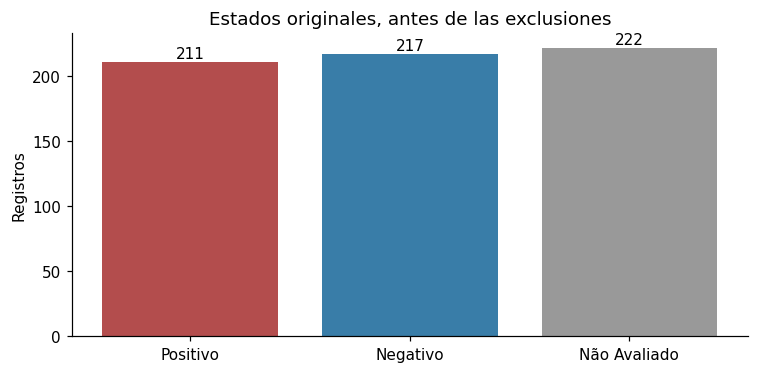

In [5]:
classes = original.groupby(['clase_codigo', 'clase_original']).size().rename('n').reset_index()
classes['porcentaje'] = 100 * classes.n / len(original)
display(classes.round(2))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(classes.clase_original, classes.n, color=['#b34d4d', '#397da8', '#999999'])
ax.set(ylabel='Registros', title='Estados originales, antes de las exclusiones')
for i, n in enumerate(classes.n):
    ax.text(i, n + 3, str(n), ha='center')
plt.tight_layout()
plt.show()

El original contiene 211 positivos, 217 negativos y 222 no evaluados. La cercanía entre positivos y negativos globales no garantiza el mismo balance por fecha, ubicación o partición. Esta auditoría general describe la fuente; las decisiones exploratorias se limitan al desarrollo en el segundo notebook. El protocolo concreto de confirmación agronómica de cada positivo sigue sin estar acreditado.

## 5. Variables meteorológicas y cobertura

Los diarios contienen 24 horas válidas por día local. Agregamos medias, mínimos, máximos y precipitación acumulada según la tabla siguiente. Las componentes del viento usan dirección meteorológica de procedencia: $u=-v\,\sin(\theta)$ y $v_{N}=-v\,\cos(\theta)$. La velocidad y sus componentes se expresan en m/s; una componente negativa indica sentido, no un error.

In [6]:
units = ['%'] * 3 + ['°C'] * 3 + ['mm'] + ['m/s'] * 3
display(pd.DataFrame({'variable': FEATURES, 'unidad': units,
                      'agregación_ventana': [AGGREGATIONS[f] for f in FEATURES]}))
lags = daily.groupby('id_medicion').dias_anteriores.agg(['count', 'min', 'max'])
assert lags['count'].eq(14).all() and lags['min'].eq(1).all() and lags['max'].eq(14).all()
assert np.isfinite(daily[FEATURES]).all().all()
assert (pd.to_datetime(daily.fecha_objetivo) - pd.to_datetime(daily.fecha_dato)).dt.days.eq(daily.dias_anteriores).all()
display(pd.Series({'mediciones con 14 días': len(lags), 'filas diarias': len(daily),
                   'faltantes meteorológicos': int(daily[FEATURES].isna().sum().sum()),
                   'predictores por muestra': len(FEATURES),
                   'menor lag': int(daily.dias_anteriores.min()),
                   'mayor lag': int(daily.dias_anteriores.max())}).to_frame('cobertura'))

,variable,unidad,agregación_ventana
0,hr_media_pct,%,mean
1,hr_min_pct,%,min
2,hr_max_pct,%,max
3,temperatura_media_c,°C,mean
4,temperatura_min_c,°C,min
5,temperatura_max_c,°C,max
6,precipitacion_mm,mm,sum
7,viento_vel_media_10m_ms,m/s,mean
8,viento_u_media_10m_ms,m/s,mean
9,viento_v_media_10m_ms,m/s,mean


,cobertura
mediciones con 14 días,428
filas diarias,5992
faltantes meteorológicos,0
predictores por muestra,10
menor lag,1
mayor lag,14


Las 428 mediciones con meteorología aportan 5.992 filas diarias completas. Las ventanas terminan en t−1: el clima de t y los días entre t y t+7 no entran en los predictores. ERA5 es un reanálisis espacial retrospectivo y no una medición meteorológica de la parcela. Las horas de mojado foliar no forman parte de estos experimentos.

## 6. Reconstrucción reproducible de h0 y h7

Usamos las muestras construidas por `procesar_datos.py` y sus controles oficiales de integridad. No sobrescribimos fuentes ni artefactos ni reconstruimos productos durante la lectura académica. En **h0**, la etiqueta corresponde a t. En **h7**, exigimos una observación evaluada en la misma ubicación **exactamente en t+7**; una visita posterior no sustituye la fecha faltante. La muestra necesita también un resultado evaluado en t.

In [7]:
verify_samples(samples)
population = samples.groupby(['horizonte_dias', 'ventana_dias']).agg(
    muestras=('muestra_id', 'nunique'), negativos=('y', lambda x: x.eq(0).sum()),
    positivos=('y', 'sum'), ubicaciones=('ubicacion_id', 'nunique'))
display(population)
exact_days = (pd.to_datetime(samples.fecha_objetivo) - pd.to_datetime(samples.fecha_referencia)).dt.days
assert exact_days.eq(samples.horizonte_dias).all()
display(pd.crosstab(samples.horizonte_dias, exact_days).rename_axis(columns='días hasta etiqueta'))

muestras  negativos  positivos  ubicaciones
horizonte_dias ventana_dias                                             
0              7                  428        217        211           22
               14                 428        217        211           22
7              7                  362        179        183           22
               14                 362        179        183           22

días hasta etiqueta,0,7
horizonte_dias,,
0,856,0
7,0,724


La construcción oficial conserva 428 muestras h0 y 362 h7, cada una representada con dos ventanas. Las 1.580 filas experimentales no equivalen a 1.580 objetivos independientes. H0 y h7 tienen poblaciones diferentes; compararlos directamente como si fueran la misma tarea ocultaría el efecto de las exclusiones.

## 7. Exclusiones y alcance del horizonte futuro

Presentamos los motivos por horizonte, contando una exclusión por observación y horizonte, no por ventana. El subconjunto h7 que parte de un negativo es auxiliar; no reemplaza la población oficial ni representa un experimento nuevo.

In [8]:
display(exclusions.groupby(['horizonte_dias', 'motivo']).size().rename('exclusiones').to_frame())
h7 = samples.query('horizonte_dias == 7 and ventana_dias == 7')
auxiliary = h7[h7.resultado_t.eq(0)]
display(pd.DataFrame({'población': ['h7 completo', 'h7 auxiliar desde negativo'],
                      'n': [len(h7), len(auxiliary)],
                      'negativos_en_t_mas_7': [int(h7.y.eq(0).sum()), int(auxiliary.y.eq(0).sum())],
                      'positivos_en_t_mas_7': [int(h7.y.eq(1).sum()), int(auxiliary.y.eq(1).sum())]}))

exclusiones
horizonte_dias motivo                             
0              referencia_no_evaluado          222
7              objetivo_no_evaluado             56
               objetivo_sin_registro            10
               referencia_no_evaluado          222

,población,n,negativos_en_t_mas_7,positivos_en_t_mas_7
0,h7 completo,362,179,183
1,h7 auxiliar desde negativo,188,131,57


En h0 se excluyen 222 referencias no evaluadas. En h7 se suman 56 objetivos no evaluados y 10 sin registro exacto, además de las 222 referencias no evaluadas. La ausencia de visita no indica ausencia de roya. H7 completo incluye positivos en t: predice el estado registrado futuro, no exclusivamente la aparición desde un estado negativo ni una primera infección.

## 8. Particiones temporales y purga

Las particiones están fijadas antes del modelado. Los tres bloques contienen seis fechas semanales de **etiqueta**: 18/08–22/09, 29/09–03/11 y 10/11–15/12 de 2025. En h7 las referencias se sitúan siete días antes. Exigimos que la última etiqueta de entrenamiento sea anterior al inicio de referencia de validación menos 14 días y que las ventanas meteorológicas no se solapen entre esos roles.

Enero–marzo de 2026 se conserva como **evaluación histórica previamente observada**, no como una prueba inédita. Mostramos sus tamaños aprobados para describir el diseño, sin explorarlo para elegir variables o parámetros.

In [9]:
from procesar_datos import check_separation

frames = {(h, 14): samples.query('horizonte_dias == @h and ventana_dias == 14').set_index('muestra_id', drop=False) for h in [0, 7]}
cols = ['horizonte', 'bloque', 'rol', 'n', 'negativos', 'positivos', 'ubicaciones',
        'etiqueta_inicio', 'etiqueta_fin', 'dias_inclusivos', 'fechas_observadas']
display(summary[cols].fillna('—'))
separation = []
for h in [0, 7]:
    frame = frames[(h, 14)]
    for block in ['1', '2', '3', 'historico']:
        split = partitions[str(h)][block]
        train = frame.loc[split['train_ids']]
        valid = frame.loc[split['validation_ids']]
        check_separation(train, valid)
        last_label = pd.to_datetime(train.fecha_objetivo).max()
        first_reference = pd.to_datetime(valid.fecha_referencia).min()
        separation.append({'horizonte': h, 'bloque': block,
            'última_etiqueta_train': last_label.date(), 'primera_referencia_valid': first_reference.date(),
            'separación_días': (first_reference-last_label).days,
            'purga_cumplida': last_label < first_reference-pd.Timedelta(days=14)})
display(pd.DataFrame(separation))

,horizonte,bloque,rol,n,negativos,positivos,ubicaciones,etiqueta_inicio,etiqueta_fin,dias_inclusivos,fechas_observadas
0,0,historico,entrenamiento,359,188.0,171.0,22.0,2024-09-02,2025-12-15,470.0,37.0
1,0,historico,evaluacion_historica,66,29.0,37.0,12.0,2026-01-05,2026-03-02,57.0,9.0
2,0,historico,purga,3,0.0,3.0,3.0,2025-12-22,2025-12-22,1.0,1.0
3,0,1,entrenamiento,164,78.0,86.0,17.0,2024-09-02,2025-01-06,127.0,18.0
4,0,1,validacion,38,23.0,15.0,8.0,2025-08-18,2025-09-22,36.0,6.0
5,0,1,purga,2,2.0,0.0,2.0,2025-08-11,2025-08-11,1.0,1.0
6,0,2,entrenamiento,188,95.0,93.0,17.0,2024-09-02,2025-09-08,372.0,23.0
7,0,2,validacion,55,29.0,26.0,12.0,2025-09-29,2025-11-03,36.0,6.0
8,0,2,purga,16,8.0,8.0,8.0,2025-09-15,2025-09-22,8.0,2.0
9,0,3,entrenamiento,239,120.0,119.0,18.0,2024-09-02,2025-10-20,414.0,29.0


,horizonte,bloque,última_etiqueta_train,primera_referencia_valid,separación_días,purga_cumplida
0,0,1,2025-01-06,2025-08-18,224,True
1,0,2,2025-09-08,2025-09-29,21,True
2,0,3,2025-10-20,2025-11-10,21,True
3,0,historico,2025-12-15,2026-01-05,21,True
4,7,1,2024-12-23,2025-08-11,231,True
5,7,2,2025-09-01,2025-09-22,21,True
6,7,3,2025-10-13,2025-11-03,21,True
7,7,historico,2025-12-15,2026-01-05,21,True


Cada bloque de validación cubre 35 días transcurridos, o 36 días calendario incluyendo ambos extremos, con seis fechas observadas. El primer entrenamiento procede de la campaña anterior debido al intervalo prolongado sin registros; seis fechas semanales no implican monitoreo diario continuo. Los bloques conservan ambas clases. La misma ubicación puede aparecer en desarrollo y evaluación: evaluamos transferencia temporal, no generalización a ubicaciones nuevas. La purga técnica se cumple, pero la disponibilidad operacional de las etiquetas sigue sin acreditarse.

## Conclusión de la auditoría

Las muestras y particiones se construyen con los scripts oficiales; los controles académicos verifican identidades, cobertura y separación temporal. Las limitaciones centrales son la semántica de la fecha, la incertidumbre de identidad física por coordenadas, la cobertura desigual y el carácter retrospectivo de la meteorología. Con estas condiciones, continuamos con un EDA limitado al desarrollo.